# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import MaxNLocator

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

import warnings
warnings.filterwarnings("ignore")



# Load the Dataset

In [2]:
data  = pd.read_csv("nigerian-songs.csv")
data.head()

,name,album,artist,artist_top_genre,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
0,Sparky,Mandy & The Jungle,Cruel Santino,alternative r&b,2019,144000,48,0.666,0.8510,0.420,0.534000,0.1100,-6.699,0.0829,133.015,5
1,shuga rush,EVERYTHING YOU HEARD IS TRUE,Odunsi (The Engine),afropop,2020,89488,30,0.710,0.0822,0.683,0.000169,0.1010,-5.640,0.3600,129.993,3
2,LITT!,LITT!,AYLØ,indie r&b,2018,207758,40,0.836,0.2720,0.564,0.000537,0.1100,-7.127,0.0424,130.005,4
3,Confident / Feeling Cool,Enjoy Your Life,Lady Donli,nigerian pop,2019,175135,14,0.894,0.7980,0.611,0.000187,0.0964,-4.961,0.1130,111.087,4
4,wanted you,rare.,Odunsi (The Engine),afropop,2018,152049,25,0.702,0.1160,0.833,0.910000,0.3480,-6.044,0.0447,105.115,4


In [3]:
data.isnull().sum()

name                0
album               0
artist              0
artist_top_genre    0
release_date        0
length              0
popularity          0
danceability        0
acousticness        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
time_signature      0
dtype: int64

The dataset has no missing values.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              530 non-null    str    
 1   album             530 non-null    str    
 2   artist            530 non-null    str    
 3   artist_top_genre  530 non-null    str    
 4   release_date      530 non-null    int64  
 5   length            530 non-null    int64  
 6   popularity        530 non-null    int64  
 7   danceability      530 non-null    float64
 8   acousticness      530 non-null    float64
 9   energy            530 non-null    float64
 10  instrumentalness  530 non-null    float64
 11  liveness          530 non-null    float64
 12  loudness          530 non-null    float64
 13  speechiness       530 non-null    float64
 14  tempo             530 non-null    float64
 15  time_signature    530 non-null    int64  
dtypes: float64(8), int64(4), str(4)
memory usage: 66.4 KB


The column release_date is actually the release year. I will just rename that for clarity.

In [5]:
data.rename(columns = {"release_date": "release_year"}, inplace = True)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              530 non-null    str    
 1   album             530 non-null    str    
 2   artist            530 non-null    str    
 3   artist_top_genre  530 non-null    str    
 4   release_year      530 non-null    int64  
 5   length            530 non-null    int64  
 6   popularity        530 non-null    int64  
 7   danceability      530 non-null    float64
 8   acousticness      530 non-null    float64
 9   energy            530 non-null    float64
 10  instrumentalness  530 non-null    float64
 11  liveness          530 non-null    float64
 12  loudness          530 non-null    float64
 13  speechiness       530 non-null    float64
 14  tempo             530 non-null    float64
 15  time_signature    530 non-null    int64  
dtypes: float64(8), int64(4), str(4)
memory usage: 66.4 KB


In [6]:
data.describe()

,release_year,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
count,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000
mean,2015.390566,222298.169811,17.507547,0.741619,0.265412,0.760623,0.016305,0.147308,-4.953011,0.130748,116.487864,3.986792
std,3.131688,39696.822259,18.992212,0.117522,0.208342,0.148533,0.090321,0.123588,2.464186,0.092939,23.518601,0.333701
min,1998.000000,89488.000000,0.000000,0.255000,0.000665,0.111000,0.000000,0.028300,-19.362000,0.027800,61.695000,3.000000
25%,2014.000000,199305.000000,0.000000,0.681000,0.089525,0.669000,0.000000,0.075650,-6.298750,0.059100,102.961250,4.000000
50%,2016.000000,218509.000000,13.000000,0.761000,0.220500,0.784500,0.000004,0.103500,-4.558500,0.097950,112.714500,4.000000
75%,2017.000000,242098.500000,31.000000,0.829500,0.403000,0.875750,0.000234,0.164000,-3.331000,0.177000,125.039250,4.000000
max,2020.000000,511738.000000,73.000000,0.966000,0.954000,0.995000,0.910000,0.811000,0.582000,0.514000,206.007000,5.000000


It is worth noting that popularity can be 0. I will remove all rows that have a popularity of 0 later in the EDA.

In [7]:
shape = data.shape
print("The dataset has {} rows and {} columns".format(shape[0], shape[1]))

The dataset has 530 rows and 16 columns


# Exploratory Data Analysis

Text(0.5, 1.0, 'Top Genres')

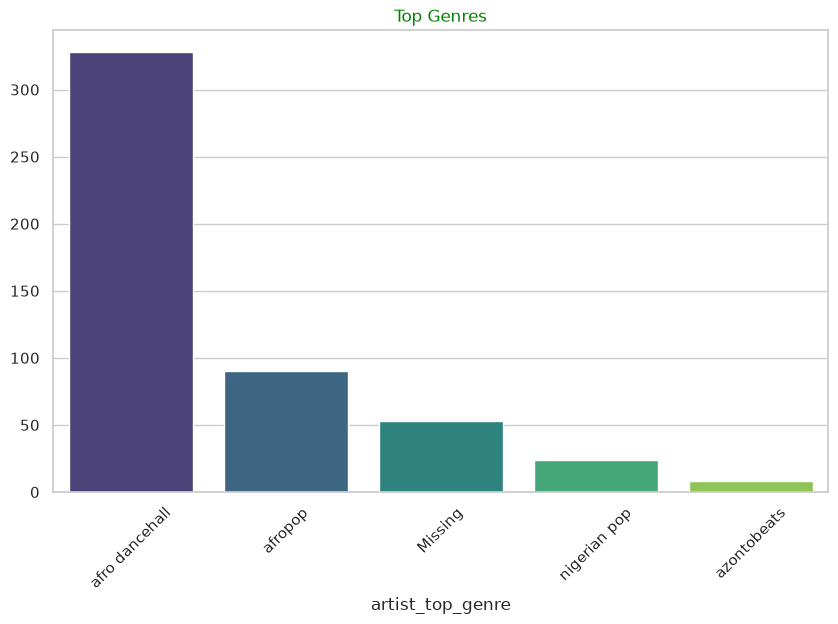

In [8]:
# visualise genre distribution
top_genres = data["artist_top_genre"].value_counts()[:5]

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.index, y = top_genres.values, palette="viridis")
plt.xticks(rotation=45)
plt.title("Top Genres", color = "Green")


The dataset contains some rows with missing artist_top_genre. I will remove these rows for now.

In [9]:
data = data[data["artist_top_genre"] != "Missing"]
data.shape

(477, 16)

Text(0.5, 1.0, 'Top 5 Artist Genres')

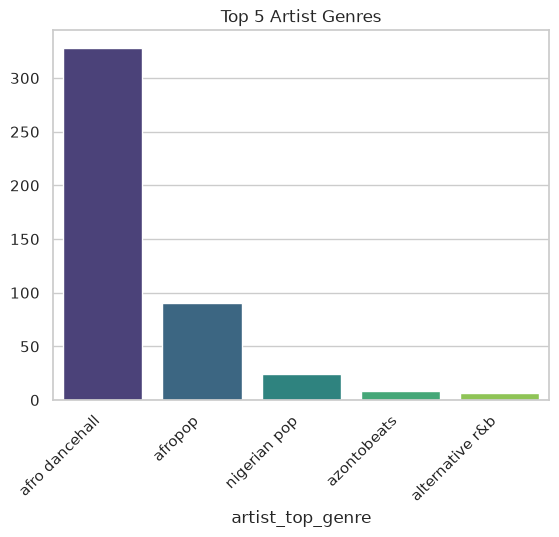

In [10]:
# get the top 5 genres after removing the "Missing" category.

top_genres = data["artist_top_genre"].value_counts()[:5]
sns.barplot(x=top_genres.index, y = top_genres.values, palette="viridis")
plt.xticks(rotation = 45, horizontalalignment="right")
plt.title("Top 5 Artist Genres")

The top 3 genres dominate the dataset. For this notebook, I will concentrate on `afro dancehall`, `afropop` and `nigerian pop`.  I will also filter the dataset to remove any row with a popularity of 0.

In [11]:
focus_genres = data["artist_top_genre"].value_counts().index[:3]


# focus on the top 3 genres and popularity is greater than 0.
data = data[
    data["artist_top_genre"].isin(focus_genres)&
    (data["popularity"] > 0)
]



In [12]:
data.describe()

,release_year,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
count,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000,286.000000
mean,2015.559441,222369.625874,28.174825,0.745584,0.264936,0.761521,0.012772,0.143072,-4.921308,0.130308,116.289706,3.975524
std,3.356319,39451.766284,17.732640,0.112230,0.203358,0.143668,0.080587,0.113716,2.402783,0.094138,23.524412,0.318046
min,2001.000000,89488.000000,1.000000,0.255000,0.000665,0.111000,0.000000,0.028300,-19.362000,0.030400,69.279000,3.000000
25%,2014.000000,198518.750000,14.000000,0.687250,0.088850,0.675750,0.000000,0.074675,-6.077000,0.056675,102.950500,4.000000
50%,2016.000000,219175.500000,27.500000,0.761000,0.228500,0.781000,0.000005,0.103000,-4.551500,0.096150,110.031500,4.000000
75%,2018.000000,246822.000000,40.750000,0.829750,0.395750,0.872750,0.000234,0.163500,-3.297250,0.176750,125.001750,4.000000
max,2020.000000,396226.000000,73.000000,0.951000,0.871000,0.995000,0.910000,0.659000,-0.116000,0.514000,206.007000,5.000000


Text(0.5, 1.0, 'Artist Top Genre')

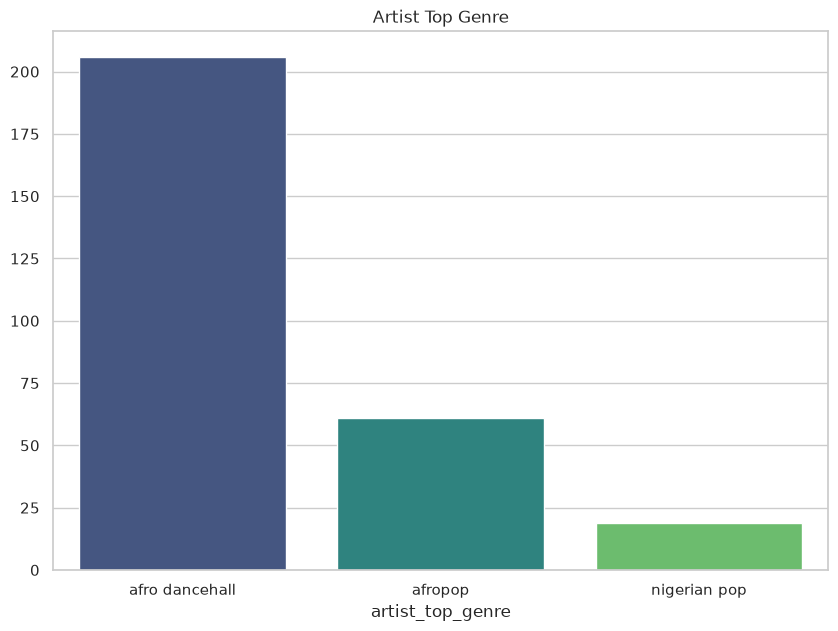

In [13]:
# check for correlation
plt.figure(figsize=(10,7))
top_genres=data["artist_top_genre"].value_counts()
sns.barplot(x=top_genres.index, y=top_genres.values, palette="viridis")
plt.title("Artist Top Genre")

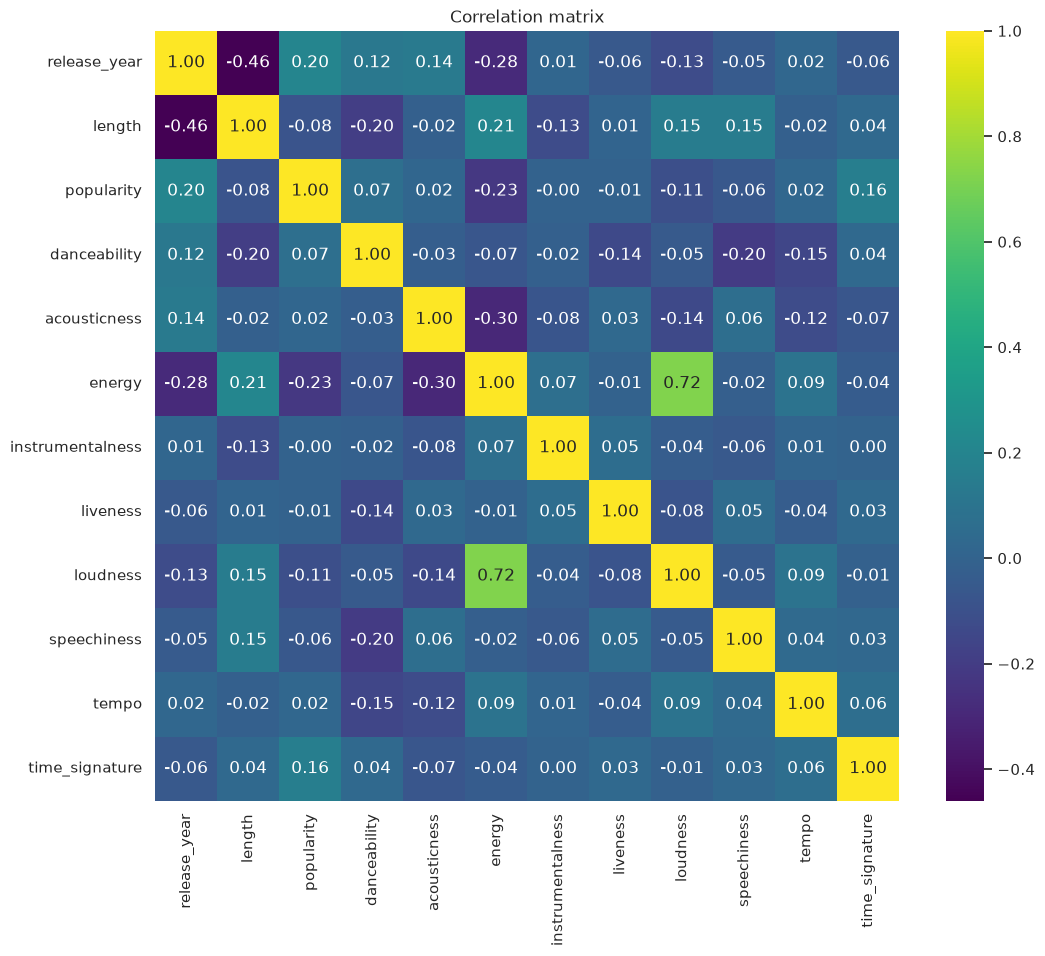

In [14]:
corr_matrix = data.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='viridis')
plt.title("Correlation matrix")
plt.show()

From the correlation matrix, the following can be observed, though unexpected:
1. Newer releases tend to have shorter track lengths, while older releases tend to have longer tracks.
2. Newer tracks in the dataset tend to have slightly lower energy scores.

I'll investigate this further using scatter plots.

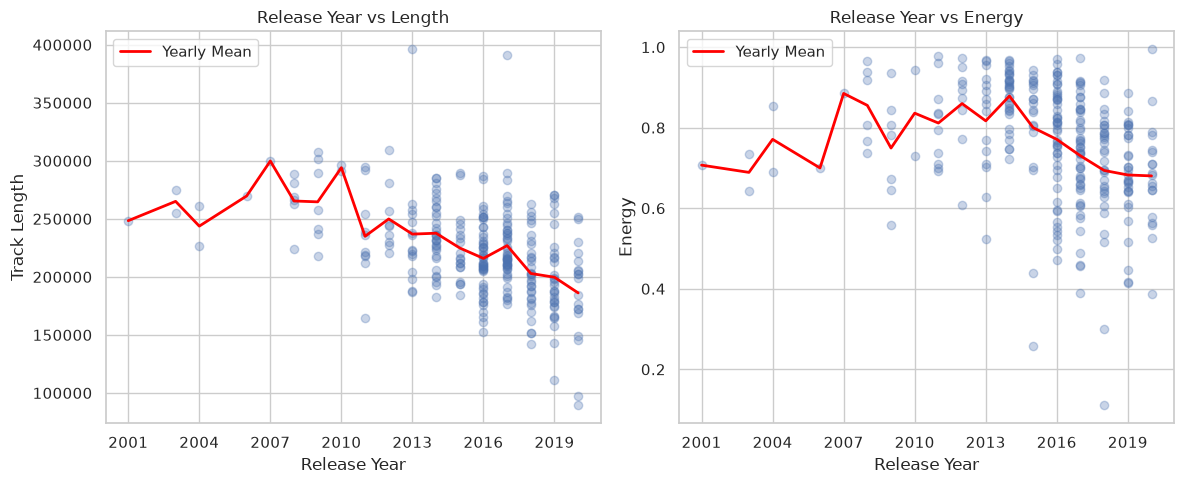

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Calculate yearly means
yearly_means = data.groupby("release_year")[["length", "energy"]].mean()

# Release Year vs Length
axes[0].scatter(data["release_year"], data["length"], alpha=0.3)
axes[0].plot(
    yearly_means.index,
    yearly_means["length"],
    color="red",
    linewidth=2,
    label="Yearly Mean"
)
axes[0].set_title("Release Year vs Length")
axes[0].set_xlabel("Release Year")
axes[0].set_ylabel("Track Length")
axes[0].legend()

# Release Year vs Energy
axes[1].scatter(data["release_year"], data["energy"], alpha=0.3)
axes[1].plot(
    yearly_means.index,
    yearly_means["energy"],
    color="red",
    linewidth=2,
    label="Yearly Mean"
)
axes[1].set_title("Release Year vs Energy")
axes[1].set_xlabel("Release Year")
axes[1].set_ylabel("Energy")
axes[1].legend()

for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)

plt.tight_layout()
plt.show()

## Relationship between popularity and other features.

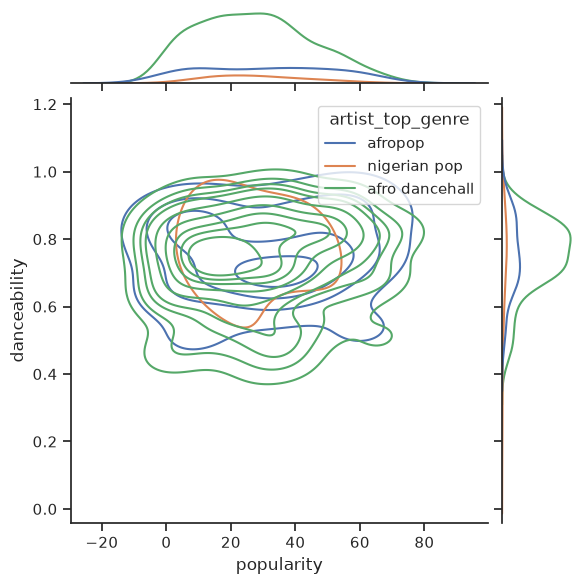

In [16]:
sns.set_theme(style="ticks")

g = sns.jointplot(
    data= data,
    x = "popularity",
    y = "danceability",
    hue = "artist_top_genre",
    kind="kde"
)


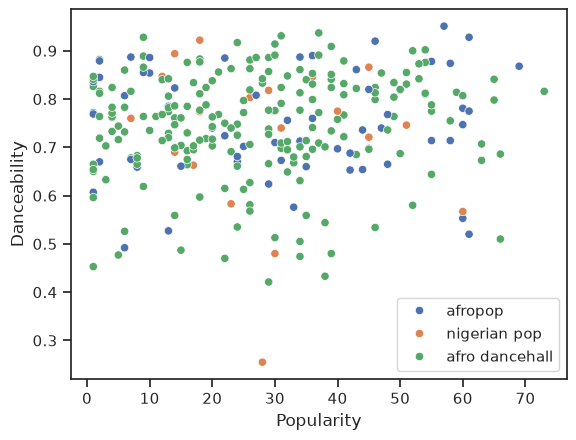

In [17]:
sns.scatterplot(data=data, x = "popularity", y = "danceability", hue="artist_top_genre")
plt.ylabel("Danceability")
plt.xlabel("Popularity")
plt.legend(loc="lower right")
plt.show()